# Предсказание правильности решения задачи учеником

**Задача:** по истории попыток ученика предсказать вероятность того, что очередная попытка решения задачи будет правильной.

**Зачем:** подбирать ученику задачи с вероятностью ошибки около 50% (не слишком лёгкие, не слишком сложные) и заранее сигнализировать преподавателю о росте вероятности ошибок.

**Данные:** попытки решения задач (`attempts`) и справочник задач (`tasks`). Разбиение по времени: обучение (недели 0–27), тест (недели 28 и позже).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
TEST_WEEK_START = 28

## Данные и feature engineering

- Целевая переменная `is_correct`.
- Пропуски в `time_sec` удаляем: без времени решения попытка неинформативна.
- `declared_difficulty` заполняем медианой по теме.
- Историю ученика считаем по неделям: `hist_acc` точность **до начала текущей недели** (кумулятив по прошлым неделям), чтобы не подглядывать в текущую неделю.

In [2]:
attempts = pd.read_csv("../data/clean/attempts.csv")
attempts["ts"] = pd.to_datetime(attempts["ts"])
tasks = pd.read_csv("../data/raw/tasks.csv")

df = attempts.merge(tasks, on="task_id", how="inner")
df["week"] = (df["ts"] - df["ts"].min()).dt.days // 7
df = df.drop(columns=["Unnamed: 0"])
df = pd.get_dummies(df, columns=["source"], dtype=int, drop_first=True)
df = df.dropna(subset=["time_sec"])

df["declared_difficulty"] = df["declared_difficulty"].fillna(
    df.groupby("topic")["declared_difficulty"].transform("median")
)

student_week = (
    df.groupby(["student_id", "week"])["is_correct"]
      .agg(["count", "sum"])
      .reset_index()
)
student_week["count_cum"] = student_week.groupby("student_id")["count"].cumsum()
student_week["sum_cum"] = student_week.groupby("student_id")["sum"].cumsum()
student_week["prev_attempts"] = student_week.groupby("student_id")["count_cum"].shift(1)
student_week["prev_correct"] = student_week.groupby("student_id")["sum_cum"].shift(1)
student_week["hist_acc"] = student_week["prev_correct"] / student_week["prev_attempts"]

df = df.merge(
    student_week[["student_id", "week", "prev_attempts", "prev_correct", "hist_acc"]],
    on=["student_id", "week"],
    how="left",
)
df = df.dropna(subset=["hist_acc"])

## Разбиение train/test по времени

Обучаем на неделях < 28, тестируем на неделях ≥ 28. Такой сплит честнее случайного: модель не видит будущее.

In [3]:
drop_cols = ["is_correct", "attempt_id", "task_id", "ts",
             "error_type", "statement", "task_type", "reference_solution"]

X = df.drop(columns=drop_cols)
X = pd.get_dummies(X, columns=["topic", "subject"], dtype=int, drop_first=True)
X1 = X.drop(columns=["student_id"])

y = df["is_correct"]

train_mask = X["week"] < TEST_WEEK_START
test_mask = X["week"] >= TEST_WEEK_START

X_train, X_test = X[train_mask], X[test_mask]
X1_train, X1_test = X1[train_mask], X1[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

## Бейзлайны

Сравниваем модели с тремя простыми стратегиями:
- константа (средняя точность на train),
- средняя точность по задаче (task_rate),
- средняя точность по ученику (student_rate).

In [4]:
task_rate = df[train_mask].groupby("task_id")["is_correct"].mean()
student_rate = df[train_mask].groupby("student_id")["is_correct"].mean()

pred_const = np.full(len(y_test), y_train.mean())
pred_task = df[test_mask]["task_id"].map(task_rate)
pred_student = df[test_mask]["student_id"].map(student_rate)

for name, p in [("const", pred_const), ("task_rate", pred_task), ("student_rate", pred_student)]:
    print(f"{name:14s} AUC={roc_auc_score(y_test, p):.4f}  log_loss={log_loss(y_test, p):.4f}")

const          AUC=0.5000  log_loss=0.6760
task_rate      AUC=0.6289  log_loss=0.6496
student_rate   AUC=0.6575  log_loss=0.6400


## Модели

Две модели: логистическая регрессия (быстрый бейзлайн) и gradient boosting (основная модель). Признаки масштабируем для LR; деревьям масштаб не важен.

In [5]:
scaler = StandardScaler()
X1_train_s = scaler.fit_transform(X1_train)
X1_test_s = scaler.transform(X1_test)

lr = LogisticRegression(random_state=RANDOM_STATE)
lr.fit(X1_train_s, y_train)
pred_lr = lr.predict_proba(X1_test_s)[:, 1]

print(f"LogReg  AUC={roc_auc_score(y_test, pred_lr):.4f}  log_loss={log_loss(y_test, pred_lr):.4f}")

LogReg  AUC=0.7058  log_loss=0.6083


Для эксперемента убираем `time_sec` и `hints_used`. Оба признака известны только **после** попытки, поэтому в реальном сценарии (предсказать до решения) их использовать нельзя. Проверяем, насколько сильно они завышают качество.

In [6]:
drop_post = ["time_sec", "hints_used"]
X_train_new = X1_train.drop(columns=drop_post)
X_test_new = X1_test.drop(columns=drop_post)

gb = HistGradientBoostingClassifier(random_state=RANDOM_STATE)
gb.fit(X_train_new, y_train)
pred_gb = gb.predict_proba(X_test_new)[:, 1]

print(f"GB      AUC={roc_auc_score(y_test, pred_gb):.4f}  log_loss={log_loss(y_test, pred_gb):.4f}")

GB      AUC=0.7094  log_loss=0.6043


## Сводка по моделям

In [7]:
results = pd.DataFrame([
    {"model": "const",       "auc": roc_auc_score(y_test, pred_const),  "log_loss": log_loss(y_test, pred_const)},
    {"model": "task_rate",   "auc": roc_auc_score(y_test, pred_task),   "log_loss": log_loss(y_test, pred_task)},
    {"model": "student_rate","auc": roc_auc_score(y_test, pred_student),"log_loss": log_loss(y_test, pred_student)},
    {"model": "LogReg",      "auc": roc_auc_score(y_test, pred_lr),     "log_loss": log_loss(y_test, pred_lr)},
    {"model": "GB",          "auc": roc_auc_score(y_test, pred_gb),     "log_loss": log_loss(y_test, pred_gb)},
]).round(4)

results.sort_values("auc", ascending=False)

,model,auc,log_loss
4,GB,0.7094,0.6043
3,LogReg,0.7058,0.6083
2,student_rate,0.6575,0.6400
1,task_rate,0.6289,0.6496
0,const,0.5000,0.6760


## Анализ ошибок по темам

Проверяем, где модель работает хуже всего, это подсказывает, для каких тем нужны отдельные признаки или больше данных.

In [8]:
test_df = pd.DataFrame({
    "topic": df[test_mask]["topic"].values,
    "y": y_test.values,
    "pred": pred_gb,
})

by_topic = (
    test_df.groupby("topic")
           .apply(lambda g: pd.Series({"n": len(g), "auc": roc_auc_score(g["y"], g["pred"])}),
                  include_groups=False)
           .reset_index()
           .sort_values("auc")
)
by_topic.round(4)

,topic,n,auc
12,lexicon,5178.0,0.6822
5,equations,6732.0,0.6854
8,function_graphs,7490.0,0.6905
19,probability_basic,7455.0,0.6907
16,orthography,4632.0,0.6910
18,probability_adv,6732.0,0.6917
11,kinematics,2047.0,0.6918
15,optics,2247.0,0.6926
1,applied_problems,7393.0,0.6930
17,planimetry_basic,7465.0,0.6958


## Важность признаков

Permutation importance на тесте: насколько падает AUC, если перемешать признак.

In [9]:
perm = permutation_importance(
    gb, X_test_new, y_test,
    scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE,
)

importance = (
    pd.DataFrame({"feature": X_test_new.columns, "importance": perm.importances_mean})
      .sort_values("importance", ascending=False)
      .reset_index(drop=True)
)
importance.head(10).round(4)

,feature,importance
0,hist_acc,0.1246
1,declared_difficulty,0.0737
2,source_self_practice,0.0068
3,prev_correct,0.0045
4,prev_attempts,0.0005
5,topic_logic,0.0005
6,ege_task_no,0.0004
7,topic_grammar_norms,0.0003
8,topic_stereometry_basic,0.0003
9,topic_applied_problems,0.0002


## Калибровка

Для задачи «подбирать задачи с вероятностью ошибки ~50%» важна не только AUC, но и калибровка: предсказанная вероятность должна совпадать с реальной частотой.

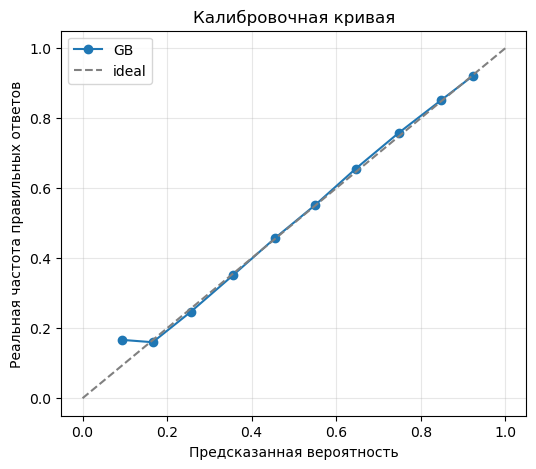

In [10]:
frac_true, mean_pred = calibration_curve(y_test, pred_gb, n_bins=10)

plt.figure(figsize=(6, 5))
plt.plot(mean_pred, frac_true, marker="o", label="GB")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="ideal")
plt.xlabel("Предсказанная вероятность")
plt.ylabel("Реальная частота правильных ответов")
plt.title("Калибровочная кривая")
plt.legend()
plt.grid(alpha=0.3)
plt.show()